# Choisir un modèle emnedding

In [1]:
from dotenv import load_dotenv
import os

load_dotenv()  
api_key = os.getenv("API_KEY")

In [2]:
from langchain_openai import OpenAIEmbeddings

emb = OpenAIEmbeddings(model="text-embedding-3-small", openai_api_key=api_key)



In [3]:
text1 = "Erreur lors du chargement du tableau de bord"
text2 = "Le tableau de bord ne s'affiche pas"
text3 = "Le client a commandé un nouveau serveur"

In [4]:
from langchain_huggingface import HuggingFaceEmbeddings

# Initialiser le modèle
embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

# Texte à transformer en vecteur
texte = "Les embeddings transforment les textes en vecteurs numériques."

# Générer l'embedding
vecteur = embeddings.embed_query(texte)

# Afficher le résultat
print("Vecteur :", vecteur)
print("Nombre de dimensions :", len(vecteur))

/home/lady/Documents/insta/ia-generative/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2080.51it/s]


Vecteur : [0.007344577927142382, 0.012218371033668518, -0.013770421966910362, -0.08484723418951035, 0.06562931090593338, 0.0973491296172142, -0.0030735291074961424, 0.01704404316842556, 0.12287764996290207, -0.023594669997692108, 0.016803942620754242, 0.07734689116477966, 0.04733765497803688, 0.03975207358598709, -0.035240959376096725, -0.0016666045412421227, -0.030984753742814064, 0.12185375392436981, -0.05071723088622093, -0.03232286125421524, -0.026260556653141975, 0.04685784503817558, 0.030920090153813362, -0.024996519088745117, 0.05476326122879982, -0.003985227085649967, -0.038935571908950806, 0.033279165625572205, -0.004376846831291914, -0.04735579341650009, 0.005402924958616495, 0.01389082707464695, -0.00397913483902812, 0.030396845191717148, -0.043669089674949646, -0.01800992526113987, 0.025305630639195442, 0.04312334209680557, -0.011982832103967667, 0.1052585020661354, -0.013828853145241737, -0.015780983492732048, -0.060159627348184586, 0.007217817008495331, 0.0574297457933425

In [5]:
vecteur1 = embeddings.embed_query(text1)
vecteur2 = embeddings.embed_query(text2)    
vecteur3 = embeddings.embed_query(text3)

print("Vecteur 1 :", vecteur1)
print("Vecteur 2 :", vecteur2)
print("Vecteur 3 :", vecteur3)

Vecteur 1 : [-0.041078872978687286, 0.01681596040725708, -0.02679152600467205, -0.07282806932926178, 0.011475298553705215, -0.012806957587599754, 0.052055925130844116, 0.07261847704648972, 0.05038607865571976, 0.0006451700464822352, 0.0561620332300663, -0.10930275171995163, 0.10026011615991592, -0.07362654060125351, -0.06174429506063461, -0.06904298067092896, -0.11613238602876663, 0.01050475612282753, 0.061915263533592224, 0.09661398828029633, -0.061383698135614395, 0.009822366759181023, -0.012531571090221405, 0.056477140635252, 0.028190484270453453, -0.035794973373413086, 0.024087529629468918, 0.001869472675025463, -0.0167289637029171, -0.09609435498714447, 0.027949420735239983, 0.00860376376658678, -0.02738077938556671, 0.0058786291629076, 0.002348442794755101, -0.004207795485854149, 0.060072995722293854, -0.042533453553915024, 0.009708226658403873, 0.06856890767812729, -0.0640903115272522, -0.06201193854212761, -0.05495505407452583, -0.02592477574944496, 0.011602559126913548, 0.0652

In [6]:
import numpy as np
def cosine_similarity(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

print("text1 :", text1)
print("text2 :", text2)
print("text3 :", text3)

print("Similarité entre vecteur 1 et vecteur 2 :", cosine_similarity(vecteur1, vecteur2))
print("Similarité entre vecteur 2 et vecteur 3 :", cosine_similarity(vecteur2, vecteur3))
print("Similarité entre vecteur 3 et vecteur 1 :", cosine_similarity(vecteur3, vecteur1))

text1 : Erreur lors du chargement du tableau de bord
text2 : Le tableau de bord ne s'affiche pas
text3 : Le client a commandé un nouveau serveur
Similarité entre vecteur 1 et vecteur 2 : 0.7742497221541795
Similarité entre vecteur 2 et vecteur 3 : 0.356065204602448
Similarité entre vecteur 3 et vecteur 1 : 0.41114652440753363


In [7]:
from sklearn.metrics.pairwise import cosine_similarity as cos 

cos([vecteur1], [vecteur3])[0][0]

np.float64(0.41114652440753363)

In [8]:
print("Similarité entre vecteur 1 et vecteur 3 :", cos([vecteur1], [vecteur2])[0][0])
print("Similarité entre vecteur 1 et vecteur 2 :", cos([vecteur1], [vecteur3])[0][0])
print("Similarité entre vecteur 2 et vecteur 3 :", cos([vecteur2], [vecteur3])[0][0])

Similarité entre vecteur 1 et vecteur 3 : 0.77424972215418
Similarité entre vecteur 1 et vecteur 2 : 0.41114652440753363
Similarité entre vecteur 2 et vecteur 3 : 0.35606520460244817


In [9]:
# Visualiser les embeddinags avec t-SNE et umap
sentences = [
    "Erreur lors du chargement du tableau de bord.",
    "Le tableau de bord ne s'affiche pas.",
    "Impossible de se connecter à l'API.",
    "Problème d'authentification sur le service.",
    "Le client a commandé un nouveau serveur.",
    "Livraison prévue pour la semaine prochaine.",
    "Le serveur physique est tombé en panne.",
    "Mise à jour réussie du système."
]

vectors = [embeddings.embed_query(sentence) for sentence in sentences]


In [10]:
from sklearn.manifold import TSNE
import numpy as np
   
vectors_np = np.array(vectors)
tsne = TSNE(n_components=2, perplexity=5, random_state=2)
points_tsne = tsne.fit_transform(vectors_np)


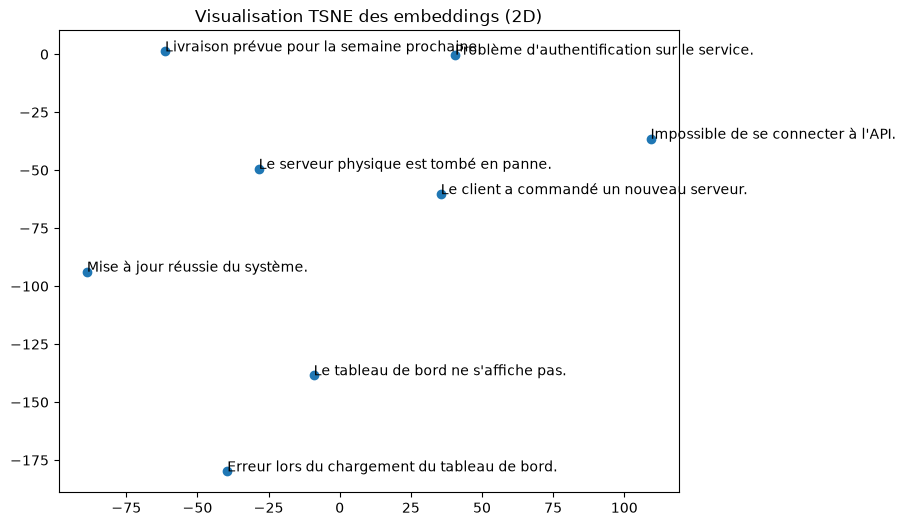

In [11]:
import matplotlib.pyplot as plt
   
plt.figure(figsize=(8,6))
plt.scatter(points_tsne[:,0], points_tsne[:,1])
for i, txt in enumerate(sentences):
    plt.annotate(txt, (points_tsne[i,0], points_tsne[i,1]))
plt.title("Visualisation TSNE des embeddings (2D)")
plt.show()

/home/lady/Documents/insta/ia-generative/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/lady/Documents/insta/ia-generative/.venv/lib/python3.12/site-packages/umap/umap_.py:2462: UserWarning: n_neighbors is larger than the dataset size; truncating to X.shape[0] - 1
  warn(


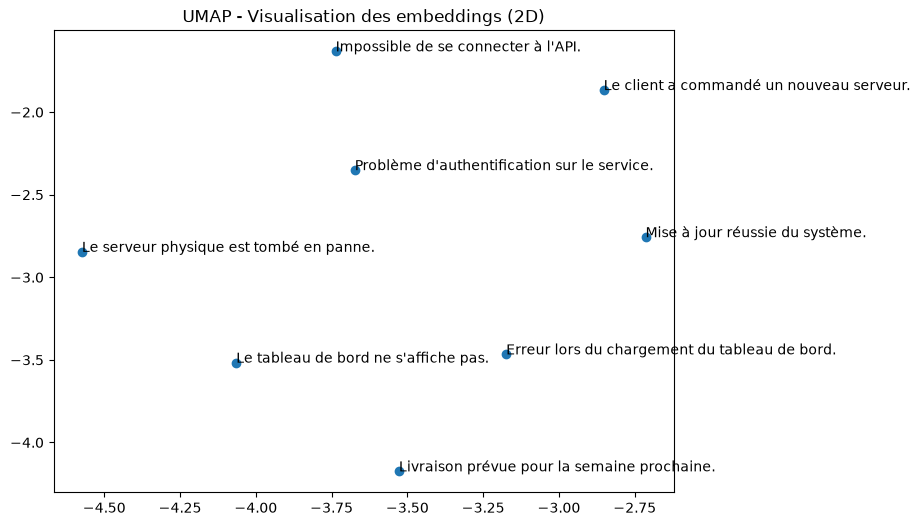

In [12]:
import umap
   
reducer = umap.UMAP(n_components=2, random_state=42)
points_umap = reducer.fit_transform(vectors)
   
plt.figure(figsize=(8,6))
plt.scatter(points_umap[:,0], points_umap[:,1])
   
for i, txt in enumerate(sentences):
        plt.annotate(txt, (points_umap[i,0], points_umap[i,1]))
   
plt.title("UMAP - Visualisation des embeddings (2D)")
plt.show()

In [13]:
from sentence_transformers import SentenceTransformer
model_local = SentenceTransformer("all-MiniLM-L6-v2")

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 4393.86it/s]


In [14]:
text_local = "la dashboard ne se charge plus."

embedding_local = model_local.encode(text_local)

print("Embedding local :", embedding_local[:10])  # Affiche les 10 premières dimensions de l'embedding

Embedding local : [-0.05242668  0.02110911 -0.00249759 -0.08575649  0.03107334  0.0183071
  0.03662715  0.04105098  0.08388628  0.06335306]


In [15]:
text_local = "le tableau de bord ne se charge plus."

embedding_local = model_local.encode(text_local)

print("Embedding local :", embedding_local[:10])  # Affiche les 10 premières dimensions de l'embedding

Embedding local : [-0.03184037  0.01374886 -0.02832196 -0.08591657  0.03002449  0.01863883
  0.06294087  0.07556868  0.02374181  0.04800683]


In [16]:
sentences = [
        "Erreur lors du chargement du tableau de bord.",
       "Le tableau de bord ne s'affiche pas.",
       "Le client a commandé un nouveau serveur."
    ]
vecs = model_local.encode(sentences)
vecs

array([[-0.04345764,  0.00539033, -0.00838229, ...,  0.01735133,
         0.0506774 ,  0.00742125],
       [ 0.00170493, -0.01072732, -0.0333443 , ...,  0.0699838 ,
         0.06510026, -0.02786067],
       [-0.06412879,  0.06582988, -0.03678605, ...,  0.0727084 ,
        -0.02667794,  0.04518537]], shape=(3, 384), dtype=float32)

# Chargement des documents

On charge les fichiers texte du dossier `data/text_files`. Le chemin est résolu depuis la racine du projet ou depuis le dossier `notebooks`. Chaque document garde son nom de fichier comme source.

In [17]:
from pathlib import Path

candidats = [Path("data/text_files"), Path("../data/text_files")]
docs_directory = next((p.resolve() for p in candidats if p.is_dir()), None)
if docs_directory is None:
    raise FileNotFoundError("Dossier data/text_files introuvable depuis le répertoire courant.")

raw_docs = []
metadatas = []
for fichier in sorted(docs_directory.glob("*.txt")):
    raw_docs.append(fichier.read_text(encoding="utf-8"))
    metadatas.append({"source": fichier.name})

print(f"{len(raw_docs)} fichier(s) chargé(s) depuis {docs_directory}")

3 fichier(s) chargé(s) depuis /home/lady/Documents/insta/ia-generative/data/text_files


## Découper les documents en passages

Le découpage limite la taille des extraits transmis au moteur de recherche et au modèle.

In [18]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

splitter = RecursiveCharacterTextSplitter(
    chunk_size=600,
    chunk_overlap=80,
    separators=["\n\n", "\n", ".", " ", ""],
)
all_chunks = splitter.create_documents(raw_docs, metadatas=metadatas)
print(f"{len(all_chunks)} passage(s) créé(s)")
if all_chunks:
    print(all_chunks[0].page_content)

17 passage(s) créé(s)
Incident Report — API Gateway Failure  
Date : 2024-01-12  
Client : TechVision  
Rédacteur : Équipe SRE / Support Niveau 2  

Résumé exécutif  
À 09:14, plusieurs services critiques ont commencé à remonter des erreurs liées à l’API Gateway.  
Entre 09:14 et 09:52, le trafic entrant a été fortement perturbé, entraînant une indisponibilité partielle des services dépendants : authentification, reporting analytique, synchronisation CRM, gestion des comptes utilisateurs.


## Indexer les passages avec des embeddings gratuits

On réutilise le modèle local `all-MiniLM-L6-v2` déclaré plus haut. Son premier usage peut télécharger les poids du modèle. Aucune clé API n’est nécessaire pour cette partie.

In [19]:
# Conversion en documents LangChain avec leur source conservée
from langchain_core.documents import Document

documents = [
    Document(page_content=chunk.page_content, metadata=chunk.metadata)
    for chunk in all_chunks
]

print(f"{len(documents)} document(s) prêt(s) pour l'indexation")

17 document(s) prêt(s) pour l'indexation


In [20]:
# Vérifier la dimension d'un embedding local
if all_chunks:
    sample_vector = embeddings.embed_query(all_chunks[0].page_content)
    print("Dimension du vecteur :", len(sample_vector))

Dimension du vecteur : 384


In [21]:
# Créer la base vectorielle Chroma à partir des passages
from langchain_chroma import Chroma

vector_store = Chroma.from_documents(
    documents=documents,
    embedding=embeddings,
    collection_name="support_docs_local",
    persist_directory="./chroma_support_docs_local",
)
print(f"Index Chroma créé avec {len(documents)} passage(s)")

Index Chroma créé avec 17 passage(s)


## Rechercher les passages pertinents

La recherche renvoie les passages les plus proches de la question selon leurs embeddings.

In [22]:
query = "Pourquoi le tableau de bord ne se charge plus ?"
results = vector_store.similarity_search(query, k=3)

for i, doc in enumerate(results, start=1):
    print(f"\n--- Résultat {i} ---")
    print("Source :", doc.metadata.get("source", "inconnue"))
    print(doc.page_content)


--- Résultat 1 ---
Source : ticket_analytics.txt
Support Ticket — Tableau de Bord Analytics  
Ticket n° 58421  
Ouvert le : 2024-02-18 — Priorité : Haute  
Utilisateur : client_internaute42  
Service impacté : analytics-service  

Description du problème  
Depuis 08h32, l’utilisateur ne parvient plus à charger le tableau de bord “Analytics”.  
L’interface renvoie systématiquement :  
504 Gateway Timeout  
Le problème persiste après plusieurs tentatives, y compris en navigation privée.

--- Résultat 2 ---
Source : ticket_analytics.txt
Analyse :
Le flux ETL "Refresh_DailyMetrics" a dépassé sa fenêtre d’exécution habituelle
(de 5 minutes à 22 minutes).  
L’origine provient d'une augmentation anormale du volume de données (x4 en 48h).

Impact :
- Les tableaux de bord n’affichent que des données partielles.
- Les équipes commerciales ne disposent pas d’indicateurs actualisés.

Mesures appliquées :
- Optimisation temporaire de la requête d’agrégation.
- Déclenchement manuel d’un recalcul.
-

## Construire le prompt et répondre avec Ollama (facultatif)

Pour générer une réponse avec un modèle gratuit exécuté en local, installez Ollama et téléchargez un modèle, par exemple `ollama pull qwen2.5:3b`. Puis installez le connecteur avec `%pip install langchain-ollama`. Cette étape ne nécessite aucun compte ni crédit OpenAI.

In [23]:
def construire_contexte(docs):
    return "\n\n".join(
        f"[Source : {doc.metadata.get('source', 'inconnue')}]\n{doc.page_content}"
        for doc in docs
    )

def construire_prompt(question, docs):
    contexte = construire_contexte(docs)
    return f"""Tu es un assistant technique interne.
Réponds uniquement à partir du contexte. Cite la source utilisée.
Si le contexte ne permet pas de répondre, dis : « Je ne sais pas ».

Contexte :
{contexte}

Question : {question}
Réponse :"""

In [24]:
# Cellule facultative : nécessite Ollama en cours d'exécution et qwen2.5:3b téléchargé.
# Décommentez ces lignes après avoir installé langchain-ollama.
# from langchain_ollama import ChatOllama
# modele_local = ChatOllama(model="qwen2.5:3b", temperature=0)
# reponse = modele_local.invoke(construire_prompt(query, results))
# print(reponse.content)

## Recherche avec scores et refus si le contexte est trop éloigné

Chroma renvoie ici une distance : plus elle est petite, plus le passage est proche de la question. Le seuil doit être ajusté aux données et au modèle utilisés.

In [25]:
query = "Quelle est la cause des retards observés dans le tableau de bord Analytics ?"
results_with_scores = vector_store.similarity_search_with_score(query, k=5)

for doc, score in results_with_scores:
    print(f"\nDistance : {score:.3f}")
    print("Source :", doc.metadata.get("source", "inconnue"))
    print(doc.page_content[:300])

THRESHOLD = 1.05
filtered_docs = [doc for doc, score in results_with_scores if score <= THRESHOLD]
if not filtered_docs:
    print("Aucun passage suffisamment proche : réponse attendue, « Je ne sais pas ». ")
else:
    print(f"{len(filtered_docs)} passage(s) retenu(s)")
    print(construire_prompt(query, filtered_docs))


Distance : 0.941
Source : ticket_analytics.txt
Observations techniques côté support  
1. Le service analytics-service affiche un pic CPU constant à 97%.  
2. La taille de la file Kafka “analytics_jobs” dépasse les seuils habituels.  
3. Plusieurs jobs ETL nocturnes ont échoué (logs : erreurs de parsing CSV).  
4. Un lot d’événements n’a pas été 

Distance : 0.944
Source : ticket_analytics.txt
Support Ticket — Tableau de Bord Analytics  
Ticket n° 58421  
Ouvert le : 2024-02-18 — Priorité : Haute  
Utilisateur : client_internaute42  
Service impacté : analytics-service  

Description du problème  
Depuis 08h32, l’utilisateur ne parvient plus à charger le tableau de bord “Analytics”.  
L’i

Distance : 0.954
Source : ticket_analytics.txt
Actions effectuées  
1. Vidage du cache applicatif.  
2. Redémarrage du service analytics-service.  
3. Exécution manuelle d’un job ETL pour débloquer la file.  
4. Purge de la file Kafka “analytics_jobs_failed”.  
5. Monitorings renforcés pendant 20 min